# Fase 3: Preparación de Datos (CRISP-DM) · Home Credit Default Risk
**Grupo 12 · Minería de Datos · UNMSM**

Este cuaderno calcula las cifras, tablas y figuras de la rúbrica (**3.1 Selección** y **3.2 Limpieza**) y aplica la limpieza v1 a `application_train`.

Requisitos: pandas, numpy, matplotlib (scipy y pyarrow opcionales). Las tablas secundarias se leen por bloques.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Parámetros

In [2]:
import gc, json, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image

try:
    from scipy import stats
except ImportError:
    stats = None

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [3]:
DATA_DIR = Path("/content/drive/MyDrive/Metodología/Minería de Datos/DATASET")     # carpeta con los CSV
OUT_DIR = Path("salida_fase3")        # carpeta de resultados
CHUNKSIZE = 1_000_000                 # filas por bloque en tablas secundarias
SOLO_APPLICATION = False              # True = prueba rápida sin tablas secundarias
GUARDAR_LIMPIO = True                 # guarda application_train_clean.parquet

UMBRAL_VACIO = 95.0       # % de nulos para excluir una columna
UMBRAL_CONSTANTE = 99.9   # % del valor dominante para excluir una columna
UMBRAL_BANDERA = 5.0      # % de nulos mínimo para crear banderas FALTA_*

(OUT_DIR / "tablas").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figuras").mkdir(parents=True, exist_ok=True)
out = OUT_DIR
resumen = {"generado": time.strftime("%Y-%m-%d %H:%M:%S"),
           "parametros": {"UMBRAL_VACIO": UMBRAL_VACIO, "UMBRAL_CONSTANTE": UMBRAL_CONSTANTE,
                          "UMBRAL_BANDERA": UMBRAL_BANDERA, "CHUNKSIZE": CHUNKSIZE}}

## 2. Configuración y utilidades
Tablas secundarias a procesar, columnas para el análisis de atípicos y funciones auxiliares.

In [4]:
SECUNDARIAS = {
    "bureau": dict(
        archivo="bureau.csv",
        llave=["SK_ID_BUREAU"],
        num=["AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT", "CREDIT_DAY_OVERDUE", "DAYS_CREDIT", "AMT_ANNUITY"],
    ),
    "bureau_balance": dict(
        archivo="bureau_balance.csv",
        llave=["SK_ID_BUREAU", "MONTHS_BALANCE"],
        num=["MONTHS_BALANCE"],
    ),
    "previous_application": dict(
        archivo="previous_application.csv",
        llave=["SK_ID_PREV"],
        num=["AMT_APPLICATION", "AMT_CREDIT", "AMT_ANNUITY", "DAYS_DECISION", "CNT_PAYMENT"],
    ),
    "POS_CASH_balance": dict(
        archivo="POS_CASH_balance.csv",
        llave=["SK_ID_PREV", "MONTHS_BALANCE"],
        num=["SK_DPD", "SK_DPD_DEF", "CNT_INSTALMENT"],
    ),
    "installments_payments": dict(
        archivo="installments_payments.csv",
        llave=["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"],
        num=["AMT_INSTALMENT", "AMT_PAYMENT", "DAYS_ENTRY_PAYMENT", "DAYS_INSTALMENT"],
    ),
    "credit_card_balance": dict(
        archivo="credit_card_balance.csv",
        llave=["SK_ID_PREV", "MONTHS_BALANCE"],
        num=["AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL", "AMT_DRAWINGS_CURRENT", "SK_DPD"],
    ),
}
OUTLIERS_APP = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_BIRTH",
    "DAYS_EMPLOYED", "CNT_CHILDREN", "CNT_FAM_MEMBERS", "OBS_30_CNT_SOCIAL_CIRCLE",
    "OBS_60_CNT_SOCIAL_CIRCLE", "AMT_REQ_CREDIT_BUREAU_QRT", "OWN_CAR_AGE",
]
TOPEAR_P999 = ["AMT_INCOME_TOTAL", "OBS_30_CNT_SOCIAL_CIRCLE", "OBS_60_CNT_SOCIAL_CIRCLE",
               "AMT_REQ_CREDIT_BUREAU_QRT"]
SENTINELA_EMPLEO = 365243
XNA_A_NAN = ["CODE_GENDER", "ORGANIZATION_TYPE"]

In [5]:
def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

def pct(a, b):
    return round(100.0 * a / b, 4) if b else float("nan")

def a_json(o):
    if hasattr(o, "item"):
        return o.item()
    return str(o)

def es_categorica(s):
    return not pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)

def resumen_num(x):
    """Estadísticos y conteo de atípicos por regla IQR (1.5x y 3x)."""
    x = np.asarray(x, dtype="float64")
    x = x[~np.isnan(x)]
    if x.size == 0:
        return {}
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    p1, p50, p99, p999 = np.percentile(x, [1, 50, 99, 99.9])
    out = {"n": int(x.size), "min": float(x.min()), "p1": float(p1), "mediana": float(p50),
           "p99": float(p99), "p99_9": float(p999), "max": float(x.max()),
           "q1": float(q1), "q3": float(q3)}
    for etiqueta, k in (("1.5", 1.5), ("3", 3.0)):
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n = int(((x < lo) | (x > hi)).sum())
        out[f"n_fuera_{etiqueta}IQR"] = n
        out[f"pct_fuera_{etiqueta}IQR"] = pct(n, x.size)
    return out

def guardar_fig(nombre, out):
    plt.tight_layout()
    plt.savefig(out / "figuras" / nombre, dpi=160)
    plt.close()

def mostrar_tabla(nombre, n=25):
    display(pd.read_csv(out / "tablas" / nombre).head(n))

def mostrar_fig(nombre, width=640):
    display(Image(filename=str(out / "figuras" / nombre), width=width))

## 3. Funciones de análisis y limpieza

In [6]:
def procesar_secundarias(data_dir, ids_train, chunksize, out, resumen):
    filas_sel, nulos_all, atipicos_sec, dups = [], [], [], []
    columnas_por_tabla = {}
    ids_bureau_train = None

    for nombre, cfg in SECUNDARIAS.items():
        ruta = data_dir / cfg["archivo"]
        if not ruta.exists():
            log(f"  ! no existe {ruta}, se omite")
            continue
        log(f"Procesando {nombre} por bloques...")
        n_total = n_train = 0
        nulos = None
        h_full, h_key = [], []
        vals = {c: [] for c in cfg["num"]}
        ids_b = []
        cols = None
        for chunk in pd.read_csv(ruta, chunksize=chunksize):
            if cols is None:
                cols = list(chunk.columns)
            n_total += len(chunk)
            nn = chunk.isna().sum()
            nulos = nn if nulos is None else nulos.add(nn, fill_value=0)
            h_full.append(pd.util.hash_pandas_object(chunk, index=False).values)
            kc = [c for c in cfg["llave"] if c in chunk.columns]
            if kc:
                h_key.append(pd.util.hash_pandas_object(chunk[kc], index=False).values)
            if "SK_ID_CURR" in chunk.columns:
                m = chunk["SK_ID_CURR"].isin(ids_train)
            elif "SK_ID_BUREAU" in chunk.columns and ids_bureau_train is not None:
                m = chunk["SK_ID_BUREAU"].isin(ids_bureau_train)
            else:
                m = pd.Series(True, index=chunk.index)
            n_train += int(m.sum())
            if nombre == "bureau":
                ids_b.append(chunk.loc[m, "SK_ID_BUREAU"].to_numpy())
            for c in vals:
                if c in chunk.columns:
                    vals[c].append(chunk[c].dropna().to_numpy(dtype="float32"))
            del chunk
        if nombre == "bureau":
            ids_bureau_train = pd.Index(np.concatenate(ids_b)) if ids_b else pd.Index([])
        columnas_por_tabla[nombre] = cols

        n_dup_full = n_total - len(np.unique(np.concatenate(h_full)))
        n_dup_key = n_total - len(np.unique(np.concatenate(h_key))) if h_key else np.nan
        dups.append({"tabla": nombre, "filas": n_total, "llave_evaluada": "+".join(cfg["llave"]),
                     "duplicados_fila_completa": n_dup_full,
                     "pct_dup_fila_completa": pct(n_dup_full, n_total),
                     "duplicados_por_llave": n_dup_key,
                     "pct_dup_llave": pct(n_dup_key, n_total) if not np.isnan(n_dup_key) else np.nan})
        filas_sel.append({"tabla": nombre, "filas_total": n_total, "filas_en_train": n_train,
                          "filas_fuera_de_train": n_total - n_train,
                          "pct_en_train": pct(n_train, n_total), "columnas": len(cols)})
        for c in cols:
            k = int(nulos.get(c, 0))
            nulos_all.append({"tabla": nombre, "columna": c, "nulos": k, "pct_nulos": pct(k, n_total)})
        for c, partes in vals.items():
            if partes:
                r = resumen_num(np.concatenate(partes))
                r.update({"tabla": nombre, "columna": c})
                atipicos_sec.append(r)
        del h_full, h_key, vals
        gc.collect()

    pd.DataFrame(filas_sel).to_csv(out / "tablas" / "seleccion_tablas.csv", index=False)
    pd.DataFrame(nulos_all).sort_values("pct_nulos", ascending=False).to_csv(
        out / "tablas" / "nulos_secundarias.csv", index=False)
    pd.DataFrame(atipicos_sec).to_csv(out / "tablas" / "atipicos_secundarias.csv", index=False)
    pd.DataFrame(dups).to_csv(out / "tablas" / "duplicados_secundarias.csv", index=False)
    resumen["secundarias"] = {"seleccion": filas_sel, "duplicados": dups}
    return columnas_por_tabla, pd.DataFrame(nulos_all)

In [7]:
def analisis_faltantes(df, out, resumen):
    n = len(df)
    nulos = df.isna().sum()
    tab = pd.DataFrame({"columna": nulos.index, "nulos": nulos.values,
                        "pct_nulos": (100 * nulos.values / n).round(4)})
    tab = tab.sort_values("pct_nulos", ascending=False)
    tab.to_csv(out / "tablas" / "nulos_application_train.csv", index=False)
    con_nulos = tab[tab.pct_nulos > 0]
    resumen["faltantes"] = {"columnas_con_nulos": int(len(con_nulos)), "columnas_totales": int(df.shape[1]),
                            "columnas_mas_50pct": int((tab.pct_nulos > 50).sum())}

    top = tab.head(20).iloc[::-1]
    plt.figure(figsize=(8, 6))
    plt.barh(top.columna, top.pct_nulos)
    plt.xlabel("% de nulos")
    plt.title("Top 20 columnas con más nulos - application_train")
    guardar_fig("F_nulos_top20.png", out)

    # Bloques de columnas con exactamente el mismo patrón de ausencia
    firmas = {}
    for c in con_nulos.columna:
        firma = int(pd.util.hash_pandas_object(df[c].isna(), index=False).sum())
        firmas.setdefault(firma, []).append(c)
    bloques = [{"bloque": i + 1, "n_columnas": len(v), "pct_nulos": float(tab.set_index("columna").loc[v[0], "pct_nulos"]),
                "columnas": ", ".join(v)} for i, v in enumerate(sorted(firmas.values(), key=len, reverse=True))]
    pd.DataFrame(bloques).to_csv(out / "tablas" / "faltantes_bloques_patron_identico.csv", index=False)

    # Correlación entre indicadores de ausencia (top 20)
    cols20 = list(tab.head(20).columna)
    corr = df[cols20].isna().astype(int).corr()
    plt.figure(figsize=(9, 8))
    plt.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    plt.xticks(range(20), cols20, rotation=90, fontsize=6)
    plt.yticks(range(20), cols20, fontsize=6)
    plt.colorbar(label="correlación de ausencia")
    plt.title("Patrón de faltantes: correlación entre indicadores de ausencia")
    guardar_fig("F_patron_faltantes_corr.png", out)

    # ¿La ausencia es informativa? Tasa de mora cuando falta vs cuando no falta
    filas = []
    for c in con_nulos[con_nulos.pct_nulos >= 1].columna:
        m = df[c].isna()
        t_f, t_n = df.loc[m, "TARGET"].mean(), df.loc[~m, "TARGET"].mean()
        p = np.nan
        if stats is not None:
            p = stats.chi2_contingency(pd.crosstab(m, df["TARGET"]))[1]
        filas.append({"columna": c, "pct_nulos": pct(int(m.sum()), n),
                      "mora_cuando_falta_%": round(100 * t_f, 3), "mora_cuando_existe_%": round(100 * t_n, 3),
                      "diferencia_pp": round(100 * (t_f - t_n), 3), "p_chi2": p})
    inf = pd.DataFrame(filas)
    inf["abs_dif"] = inf["diferencia_pp"].abs()
    inf = inf.sort_values("abs_dif", ascending=False).drop(columns="abs_dif")
    inf.to_csv(out / "tablas" / "faltantes_vs_target.csv", index=False)
    t15 = inf.head(15).iloc[::-1]
    y = np.arange(len(t15))
    plt.figure(figsize=(8, 6))
    plt.barh(y - 0.2, t15["mora_cuando_falta_%"], 0.4, label="valor ausente")
    plt.barh(y + 0.2, t15["mora_cuando_existe_%"], 0.4, label="valor presente")
    plt.yticks(y, t15.columna, fontsize=7)
    plt.xlabel("Tasa de mora (%)")
    plt.title("La ausencia ¿es informativa? (15 columnas con mayor diferencia)")
    plt.legend()
    guardar_fig("F_faltante_vs_target.png", out)

    # Nulos por fila
    nf = df.isna().sum(axis=1)
    bins = pd.cut(nf, [-1, 0, 5, 10, 20, 40, 200])
    por_fila = df.groupby(bins, observed=True)["TARGET"].agg(["size", "mean"]).reset_index()
    por_fila.columns = ["nulos_por_fila", "filas", "tasa_mora"]
    por_fila["tasa_mora"] = (100 * por_fila["tasa_mora"]).round(3)
    por_fila.to_csv(out / "tablas" / "faltantes_por_fila.csv", index=False)
    plt.figure(figsize=(7, 4))
    plt.hist(nf, bins=40)
    plt.xlabel("Nulos por solicitud")
    plt.ylabel("Solicitudes")
    plt.title("Distribución de nulos por fila - application_train")
    guardar_fig("F_nulos_por_fila.png", out)
    return tab, firmas

In [8]:
def analisis_atipicos(df, out, resumen):
    filas = []
    for c in OUTLIERS_APP:
        if c not in df.columns:
            continue
        x = df[c]
        if c == "DAYS_EMPLOYED":
            x = x[x != SENTINELA_EMPLEO]  # el centinela se trata aparte
        r = resumen_num(x.to_numpy())
        r["columna"] = c
        filas.append(r)
    tab = pd.DataFrame(filas)
    cols = ["columna"] + [c for c in tab.columns if c != "columna"]
    tab[cols].to_csv(out / "tablas" / "atipicos_application_train.csv", index=False)

    plt.figure(figsize=(8, 5))
    t = tab.sort_values("pct_fuera_3IQR")
    plt.barh(t.columna, t["pct_fuera_3IQR"])
    plt.xlabel("% de valores fuera de 3x IQR")
    plt.title("Atípicos severos por variable - application_train")
    guardar_fig("F_atipicos_pct.png", out)

    # Centinela de DAYS_EMPLOYED
    if "DAYS_EMPLOYED" in df.columns:
        m = df["DAYS_EMPLOYED"] == SENTINELA_EMPLEO
        info = {"filas_centinela": int(m.sum()), "pct": pct(int(m.sum()), len(df)),
                "mora_centinela_%": round(100 * df.loc[m, "TARGET"].mean(), 3),
                "mora_resto_%": round(100 * df.loc[~m, "TARGET"].mean(), 3)}
        if "NAME_INCOME_TYPE" in df.columns:
            info["tipos_ingreso_en_centinela"] = df.loc[m, "NAME_INCOME_TYPE"].value_counts().to_dict()
        resumen["centinela_days_employed"] = info
        plt.figure(figsize=(7, 4))
        plt.hist(df.loc[~m, "DAYS_EMPLOYED"] / -365.25, bins=60)
        plt.xlabel("Años de empleo (sin centinela)")
        plt.ylabel("Solicitudes")
        plt.title(f"DAYS_EMPLOYED: {info['filas_centinela']:,} filas con centinela {SENTINELA_EMPLEO} aparte")
        guardar_fig("F_days_employed.png", out)

def revisar_inconsistencias(df, out, resumen):
    n = len(df)
    g = lambda c: df[c] if c in df.columns else None  # noqa: E731
    reglas = []

    def regla(nombre, fn):
        try:
            m = fn()
            if m is None:
                return
            k = int(m.sum())
            reglas.append({"chequeo": nombre, "filas_afectadas": k, "pct": pct(k, n)})
        except Exception as e:  # una regla rota no debe tumbar el script
            reglas.append({"chequeo": nombre, "filas_afectadas": np.nan, "pct": f"error: {e}"})

    edad = (-df["DAYS_BIRTH"] / 365.25) if "DAYS_BIRTH" in df.columns else None
    emp = g("DAYS_EMPLOYED")
    regla("DAYS_BIRTH >= 0 (debe ser negativo)", lambda: df["DAYS_BIRTH"] >= 0)
    regla("Edad < 18 o > 100 años", lambda: (edad < 18) | (edad > 100))
    regla("DAYS_EMPLOYED = centinela 365243", lambda: emp == SENTINELA_EMPLEO)
    regla("DAYS_EMPLOYED positivo distinto del centinela", lambda: (emp > 0) & (emp != SENTINELA_EMPLEO))
    regla("Años empleado > edad", lambda: (emp < 0) & (-emp / 365.25 > edad))
    regla("Empezó a trabajar antes de los 14 años", lambda: (emp < 0) & (edad + emp / 365.25 < 14))
    regla("CODE_GENDER = XNA", lambda: df["CODE_GENDER"] == "XNA")
    regla("ORGANIZATION_TYPE = XNA", lambda: df["ORGANIZATION_TYPE"] == "XNA")
    regla("ORGANIZATION_TYPE = XNA y centinela de empleo (coinciden)",
          lambda: (df["ORGANIZATION_TYPE"] == "XNA") & (emp == SENTINELA_EMPLEO))
    regla("CNT_FAM_MEMBERS < CNT_CHILDREN", lambda: df["CNT_FAM_MEMBERS"] < df["CNT_CHILDREN"])
    regla("AMT_INCOME_TOTAL <= 0", lambda: df["AMT_INCOME_TOTAL"] <= 0)
    regla("AMT_CREDIT <= 0", lambda: df["AMT_CREDIT"] <= 0)
    regla("AMT_ANNUITY > AMT_CREDIT", lambda: df["AMT_ANNUITY"] > df["AMT_CREDIT"])
    regla("FLAG_OWN_CAR = N pero OWN_CAR_AGE informado",
          lambda: (df["FLAG_OWN_CAR"] == "N") & df["OWN_CAR_AGE"].notna())
    regla("FLAG_OWN_CAR = Y pero OWN_CAR_AGE vacío",
          lambda: (df["FLAG_OWN_CAR"] == "Y") & df["OWN_CAR_AGE"].isna())
    for c in ("EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"):
        regla(f"{c} fuera de [0,1]", lambda c=c: (df[c] < 0) | (df[c] > 1))
    for c in ("DAYS_REGISTRATION", "DAYS_ID_PUBLISH"):
        regla(f"{c} > 0 (debe ser negativo)", lambda c=c: df[c] > 0)

    # Texto con espacios o mayúsculas inconsistentes en categóricas
    for c in [c for c in df.columns if es_categorica(df[c])]:
        s = df[c].dropna().astype(str)
        k_esp = int((s != s.str.strip()).sum())
        k_caso = int(s.str.lower().nunique() != s.nunique())
        if k_esp or k_caso:
            reglas.append({"chequeo": f"{c}: espacios sobrantes / variantes de mayúsculas",
                           "filas_afectadas": k_esp, "pct": pct(k_esp, n)})
    pd.DataFrame(reglas).to_csv(out / "tablas" / "inconsistencias_application_train.csv", index=False)
    resumen["inconsistencias"] = reglas

def duplicados_application(df, out, resumen):
    d = {"filas": len(df), "duplicados_fila_completa": int(df.duplicated().sum()),
         "SK_ID_CURR_repetidos": int(df["SK_ID_CURR"].duplicated().sum())}
    pd.DataFrame([d]).to_csv(out / "tablas" / "duplicados_application_train.csv", index=False)
    resumen["duplicados_application"] = d

In [9]:
def seleccion_columnas(df, nulos_sec, umbral_vacio, umbral_const, out, resumen):
    filas = []
    for c in df.columns:
        if c in ("TARGET", "SK_ID_CURR"):
            continue
        top = df[c].value_counts(dropna=False, normalize=True)
        share = 100 * float(top.iloc[0]) if len(top) else 100.0
        if share >= umbral_const:
            filas.append({"tabla": "application_train", "columna": c,
                          "motivo": f"casi constante (valor dominante {share:.4f}%)", "decision": "excluir"})
    if nulos_sec is not None and len(nulos_sec):
        for _, r in nulos_sec[nulos_sec.pct_nulos >= umbral_vacio].iterrows():
            filas.append({"tabla": r.tabla, "columna": r.columna,
                          "motivo": f"{r.pct_nulos:.2f}% de nulos", "decision": "excluir"})
    tab = pd.DataFrame(filas, columns=["tabla", "columna", "motivo", "decision"])
    tab.to_csv(out / "tablas" / "seleccion_columnas_excluidas.csv", index=False)
    resumen["columnas_excluidas"] = len(tab)
    return tab

def limpiar_application(df, excl, firmas, umbral_flag, out, resumen, guardar):
    antes = {"filas": len(df), "columnas": df.shape[1], "nulos_totales": int(df.isna().sum().sum()),
             "memoria_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1)}
    d = df.copy()
    log_cambios = []

    # 1) Excluir columnas
    drop = [c for c in excl[excl.tabla == "application_train"].columna if c in d.columns]
    d = d.drop(columns=drop)
    log_cambios.append({"paso": "columnas excluidas", "detalle": ", ".join(drop) or "-", "filas": np.nan})

    # 2) Centinela de empleo -> NaN + bandera
    if "DAYS_EMPLOYED" in d.columns:
        m = d["DAYS_EMPLOYED"] == SENTINELA_EMPLEO
        d["FLAG_NO_EMPLEADO"] = m.astype("int8")
        d.loc[m, "DAYS_EMPLOYED"] = np.nan
        log_cambios.append({"paso": "DAYS_EMPLOYED centinela -> NaN + FLAG_NO_EMPLEADO", "detalle": "", "filas": int(m.sum())})

    # 3) XNA -> NaN
    for c in XNA_A_NAN:
        if c in d.columns:
            m = d[c] == "XNA"
            d.loc[m, c] = np.nan
            log_cambios.append({"paso": f"{c}: XNA -> NaN", "detalle": "", "filas": int(m.sum())})

    # 4) Topeo al percentil 99.9 con bandera (los topes deben recalcularse solo con train tras el split)
    comp = []
    for c in TOPEAR_P999:
        if c in d.columns:
            antes_s = d[c].copy()
            tope = float(d[c].quantile(0.999))
            m = d[c] > tope
            if m.any():
                d[f"TOPEADO_{c}"] = m.astype("int8")
                d.loc[m, c] = tope
            comp.append({"columna": c, "tope_p99_9": tope, "filas_topeadas": int(m.sum()),
                         "max_antes": float(antes_s.max()), "max_despues": float(d[c].max()),
                         "media_antes": float(antes_s.mean()), "media_despues": float(d[c].mean()),
                         "desv_antes": float(antes_s.std()), "desv_despues": float(d[c].std())})
            log_cambios.append({"paso": f"{c}: topeo p99.9", "detalle": f"tope={tope:.2f}", "filas": int(m.sum())})
    pd.DataFrame(comp).to_csv(out / "tablas" / "topeo_antes_despues.csv", index=False)
    if "AMT_INCOME_TOTAL" in df.columns:
        plt.figure(figsize=(6, 5))
        plt.boxplot([np.log10(df["AMT_INCOME_TOTAL"].clip(lower=1)),
                     np.log10(d["AMT_INCOME_TOTAL"].clip(lower=1))], tick_labels=["antes", "después"])
        plt.ylabel("log10(AMT_INCOME_TOTAL)")
        plt.title("Ingreso: antes y después del topeo p99.9")
        guardar_fig("F_ingreso_antes_despues.png", out)

    # 5) Banderas de ausencia (una por bloque de patrón idéntico, solo columnas >= umbral)
    n = len(d)
    banderas = []
    for cols in firmas.values():
        vivas = [c for c in cols if c in d.columns and d[c].isna().mean() * 100 >= umbral_flag]
        if vivas:
            nombre = f"FALTA_{vivas[0]}"
            d[nombre] = d[vivas[0]].isna().astype("int8")
            banderas.append({"bandera": nombre, "cubre_columnas": len(vivas), "pct_ausente": pct(int(d[nombre].sum()), n)})
    pd.DataFrame(banderas).to_csv(out / "tablas" / "banderas_ausencia_creadas.csv", index=False)
    log_cambios.append({"paso": "banderas FALTA_*", "detalle": f"{len(banderas)} banderas (umbral {umbral_flag}%)", "filas": np.nan})

    # 6) Tipos: categóricas -> category; numéricas reducidas
    for c in d.columns:
        if es_categorica(d[c]):
            d[c] = d[c].astype("category")
        elif pd.api.types.is_float_dtype(d[c]):
            d[c] = pd.to_numeric(d[c], downcast="float")
        elif pd.api.types.is_integer_dtype(d[c]):
            d[c] = pd.to_numeric(d[c], downcast="integer")

    despues = {"filas": len(d), "columnas": d.shape[1], "nulos_totales": int(d.isna().sum().sum()),
               "memoria_MB": round(d.memory_usage(deep=True).sum() / 1e6, 1)}
    pd.DataFrame([{"momento": "antes", **antes}, {"momento": "después", **despues}]).to_csv(
        out / "tablas" / "antes_despues_application_train.csv", index=False)
    pd.DataFrame(log_cambios).to_csv(out / "tablas" / "registro_limpieza.csv", index=False)
    resumen["limpieza"] = {"antes": antes, "despues": despues, "pasos": log_cambios}

    if guardar:
        try:
            d.to_parquet(out / "application_train_clean.parquet", index=False)
            log("Guardado application_train_clean.parquet")
        except Exception as e:
            d.to_csv(out / "application_train_clean.csv.gz", index=False)
            log(f"No se pudo guardar parquet ({e}); se guardó CSV comprimido")
    return d

def revisar_diccionario(data_dir, columnas_por_tabla, out, resumen):
    ruta = data_dir / "HomeCredit_columns_description.csv"
    if not ruta.exists():
        return
    d = pd.read_csv(ruta, encoding="latin1")
    d.columns = [c.strip() for c in d.columns]
    ctab = next((c for c in d.columns if c.lower() == "table"), None)
    crow = next((c for c in d.columns if c.lower() == "row"), None)
    if not ctab or not crow:
        return
    filas = []
    for tabla, cols in columnas_por_tabla.items():
        sel = d[d[ctab].astype(str).str.lower().str.startswith(
            "application" if tabla == "application_train" else tabla.lower())]
        dic = set(sel[crow].astype(str).str.strip())
        csv = set(cols)
        filas.append({"tabla": tabla, "cols_dicc": len(dic), "cols_csv": len(csv),
                      "en_dicc_no_csv": ", ".join(sorted(dic - csv)),
                      "en_csv_no_dicc": ", ".join(sorted(csv - dic))})
    pd.DataFrame(filas).to_csv(out / "tablas" / "diccionario_vs_csv.csv", index=False)

## 4. Carga de `application_train`

In [10]:
df = pd.read_csv(DATA_DIR / "application_train.csv")
resumen["application_train"] = {"filas": len(df), "columnas": df.shape[1],
                                "tasa_mora_%": round(100 * df["TARGET"].mean(), 4)}
columnas_por_tabla = {"application_train": list(df.columns)}
nulos_sec = None
print(df.shape, "| mora:", resumen["application_train"]["tasa_mora_%"], "%")

(307511, 122) | mora: 8.0729 %


## 5. Selección de datos (3.1): tablas secundarias
Lectura por bloques: filas en train, nulos por columna, duplicados por fila y por llave, y estadísticos de atípicos. Es la celda más lenta.

In [11]:
if not SOLO_APPLICATION:
    cols_sec, nulos_sec = procesar_secundarias(DATA_DIR, df["SK_ID_CURR"].to_numpy(), CHUNKSIZE, out, resumen)
    columnas_por_tabla.update(cols_sec)
    mostrar_tabla("seleccion_tablas.csv")
    mostrar_tabla("duplicados_secundarias.csv")
else:
    print("SOLO_APPLICATION=True: se omiten las tablas secundarias")

[10:14:53] Procesando bureau por bloques...
[10:15:05] Procesando bureau_balance por bloques...
[10:15:30] Procesando previous_application por bloques...
[10:15:49] Procesando POS_CASH_balance por bloques...
[10:16:06] Procesando installments_payments por bloques...
[10:16:36] Procesando credit_card_balance por bloques...


,tabla,filas_total,filas_en_train,filas_fuera_de_train,pct_en_train,columnas
0,bureau,1716428,1465325,251103,85.3706,17
1,bureau_balance,27299925,14701612,12598313,53.8522,3
2,previous_application,1670214,1413701,256513,84.6419,37
3,POS_CASH_balance,10001358,8543375,1457983,85.4221,8
4,installments_payments,13605401,11591592,2013809,85.1985,8
5,credit_card_balance,3840312,3227965,612347,84.0548,23


,tabla,filas,llave_evaluada,duplicados_fila_completa,pct_dup_fila_completa,duplicados_por_llave,pct_dup_llave
0,bureau,1716428,SK_ID_BUREAU,0,0.0,0,0.0000
1,bureau_balance,27299925,SK_ID_BUREAU+MONTHS_BALANCE,0,0.0,0,0.0000
2,previous_application,1670214,SK_ID_PREV,0,0.0,0,0.0000
3,POS_CASH_balance,10001358,SK_ID_PREV+MONTHS_BALANCE,0,0.0,0,0.0000
4,installments_payments,13605401,SK_ID_PREV+NUM_INSTALMENT_VERSION+NUM_INSTALME...,0,0.0,653483,4.8031
5,credit_card_balance,3840312,SK_ID_PREV+MONTHS_BALANCE,0,0.0,0,0.0000


In [12]:
revisar_diccionario(DATA_DIR, columnas_por_tabla, out, resumen)
if (out / "tablas" / "diccionario_vs_csv.csv").exists():
    mostrar_tabla("diccionario_vs_csv.csv")

,tabla,cols_dicc,cols_csv,en_dicc_no_csv,en_csv_no_dicc
0,application_train,122,122,NaN,NaN
1,bureau,19,17,"MONTHS_BALANCE, SK_BUREAU_ID, STATUS",SK_ID_BUREAU
2,bureau_balance,3,3,SK_BUREAU_ID,SK_ID_BUREAU
3,previous_application,38,37,NFLAG_MICRO_CASH,NaN
4,POS_CASH_balance,8,8,NaN,NaN
5,installments_payments,8,8,NaN,NaN
6,credit_card_balance,23,23,NaN,NaN


## 6. Valores faltantes y su patrón (3.2)

{'columnas_con_nulos': 67, 'columnas_totales': 122, 'columnas_mas_50pct': 41}


,columna,nulos,pct_nulos
0,COMMONAREA_AVG,214865,69.8723
1,COMMONAREA_MODE,214865,69.8723
2,COMMONAREA_MEDI,214865,69.8723
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4330
4,NONLIVINGAPARTMENTS_MODE,213514,69.4330
5,NONLIVINGAPARTMENTS_AVG,213514,69.4330
6,FONDKAPREMONT_MODE,210295,68.3862
7,LIVINGAPARTMENTS_AVG,210199,68.3550
8,LIVINGAPARTMENTS_MEDI,210199,68.3550
9,LIVINGAPARTMENTS_MODE,210199,68.3550


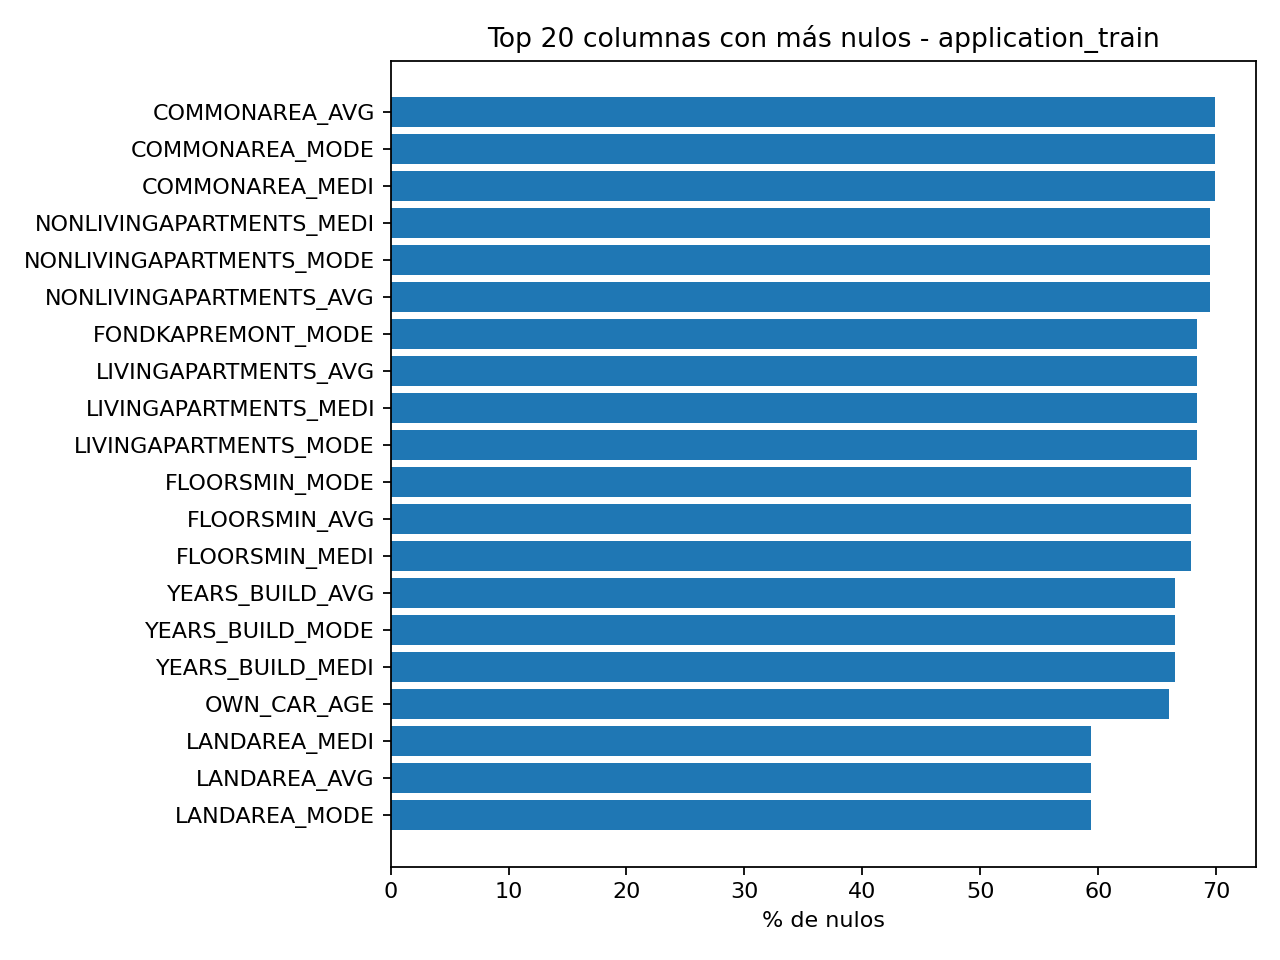

In [13]:
tab_nulos, firmas = analisis_faltantes(df, out, resumen)
print(resumen["faltantes"])
mostrar_tabla("nulos_application_train.csv", 15)
mostrar_fig("F_nulos_top20.png")

,bloque,n_columnas,pct_nulos,columnas
0,1,6,13.5016,"AMT_REQ_CREDIT_BUREAU_HOUR, AMT_REQ_CREDIT_BUR..."
1,2,4,0.3320,"DEF_60_CNT_SOCIAL_CIRCLE, OBS_60_CNT_SOCIAL_CI..."
2,3,3,69.8723,"COMMONAREA_AVG, COMMONAREA_MODE, COMMONAREA_MEDI"
3,4,3,69.4330,"NONLIVINGAPARTMENTS_MEDI, NONLIVINGAPARTMENTS_..."
4,5,3,68.3550,"LIVINGAPARTMENTS_AVG, LIVINGAPARTMENTS_MEDI, L..."
5,6,3,67.8486,"FLOORSMIN_MODE, FLOORSMIN_AVG, FLOORSMIN_MEDI"
6,7,3,66.4978,"YEARS_BUILD_AVG, YEARS_BUILD_MODE, YEARS_BUILD..."
7,8,3,59.3767,"LANDAREA_MEDI, LANDAREA_AVG, LANDAREA_MODE"
8,9,3,58.5160,"BASEMENTAREA_MODE, BASEMENTAREA_MEDI, BASEMENT..."
9,10,3,55.1792,"NONLIVINGAREA_MODE, NONLIVINGAREA_AVG, NONLIVI..."


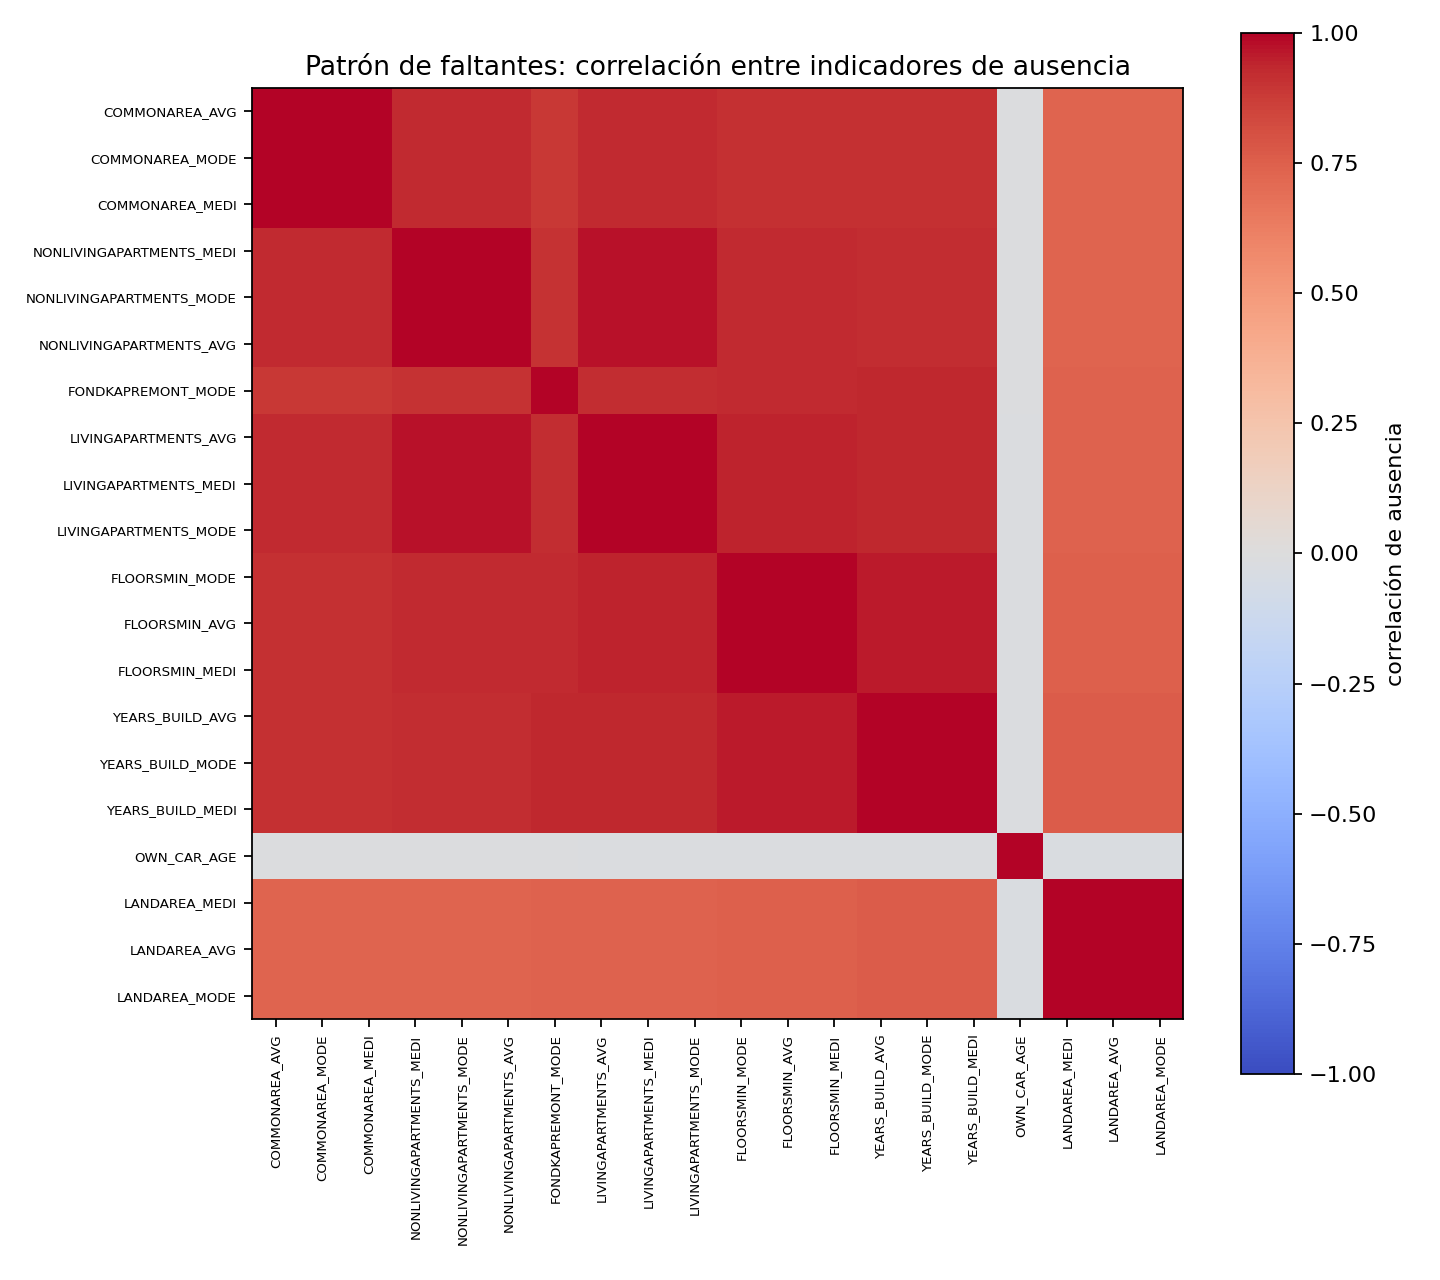

In [14]:
mostrar_tabla("faltantes_bloques_patron_identico.csv")
mostrar_fig("F_patron_faltantes_corr.png", 560)

,columna,pct_nulos,mora_cuando_falta_%,mora_cuando_existe_%,diferencia_pp,p_chi2
0,AMT_REQ_CREDIT_BUREAU_DAY,13.5016,10.337,7.719,2.618,4.915574e-74
1,AMT_REQ_CREDIT_BUREAU_HOUR,13.5016,10.337,7.719,2.618,4.915574e-74
2,AMT_REQ_CREDIT_BUREAU_WEEK,13.5016,10.337,7.719,2.618,4.915574e-74
3,AMT_REQ_CREDIT_BUREAU_MON,13.5016,10.337,7.719,2.618,4.915574e-74
4,AMT_REQ_CREDIT_BUREAU_YEAR,13.5016,10.337,7.719,2.618,4.915574e-74
5,AMT_REQ_CREDIT_BUREAU_QRT,13.5016,10.337,7.719,2.618,4.915574e-74
6,OCCUPATION_TYPE,31.3455,6.513,8.785,-2.272,4.804746e-102
7,EMERGENCYSTATE_MODE,47.3983,9.261,7.003,2.258,1.595970e-116
8,TOTALAREA_MODE,48.2685,9.234,6.990,2.244,2.722057e-115
9,ENTRANCES_AVG,50.3488,9.179,6.952,2.227,1.151497e-113


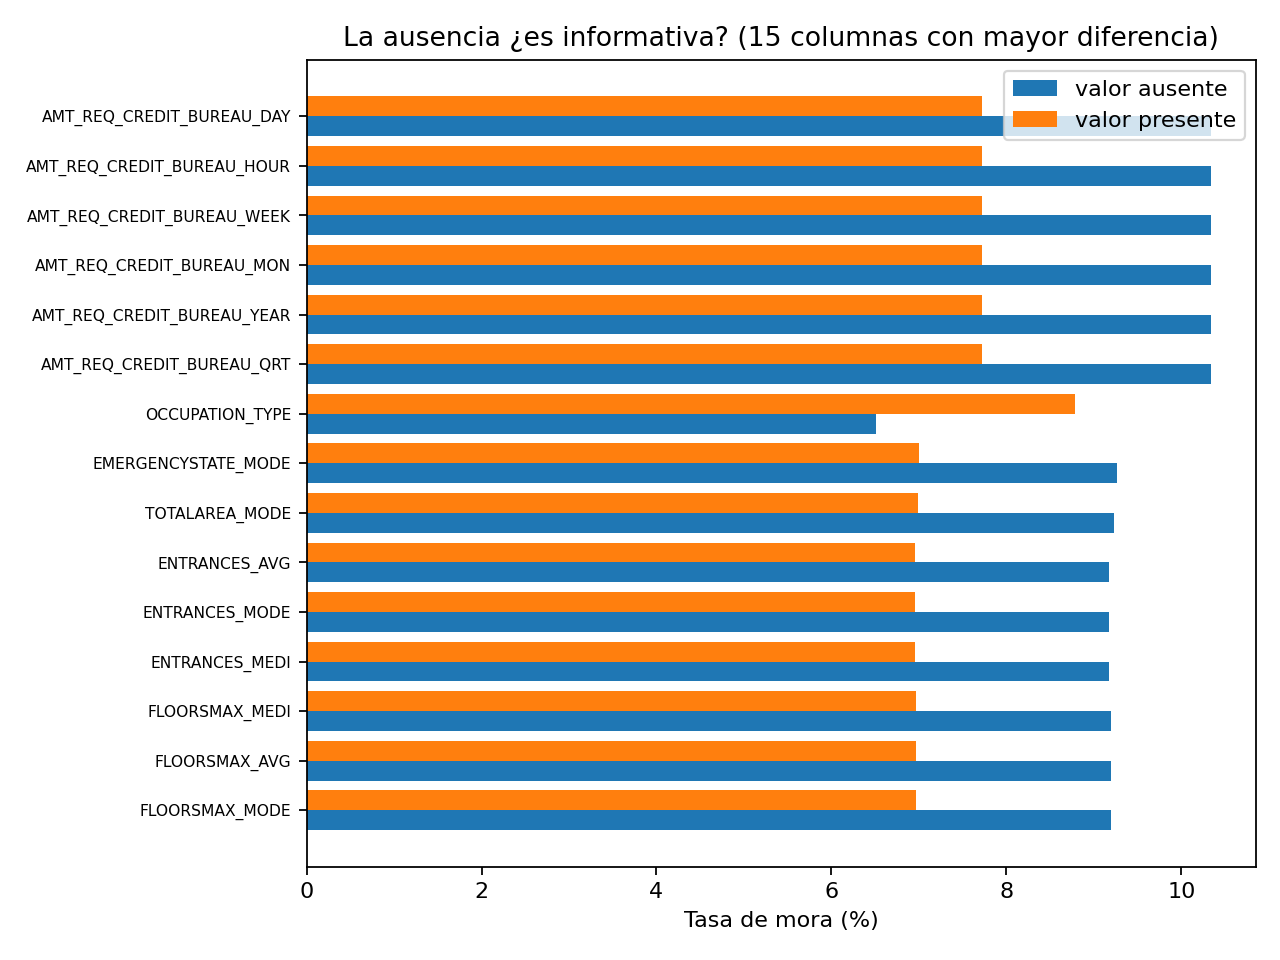

,nulos_por_fila,filas,tasa_mora
0,"(-1, 0]",8602,6.115
1,"(0, 5]",68829,6.733
2,"(5, 10]",17097,7.674
3,"(10, 20]",28776,6.787
4,"(20, 40]",33040,7.506
5,"(40, 200]",151167,9.208


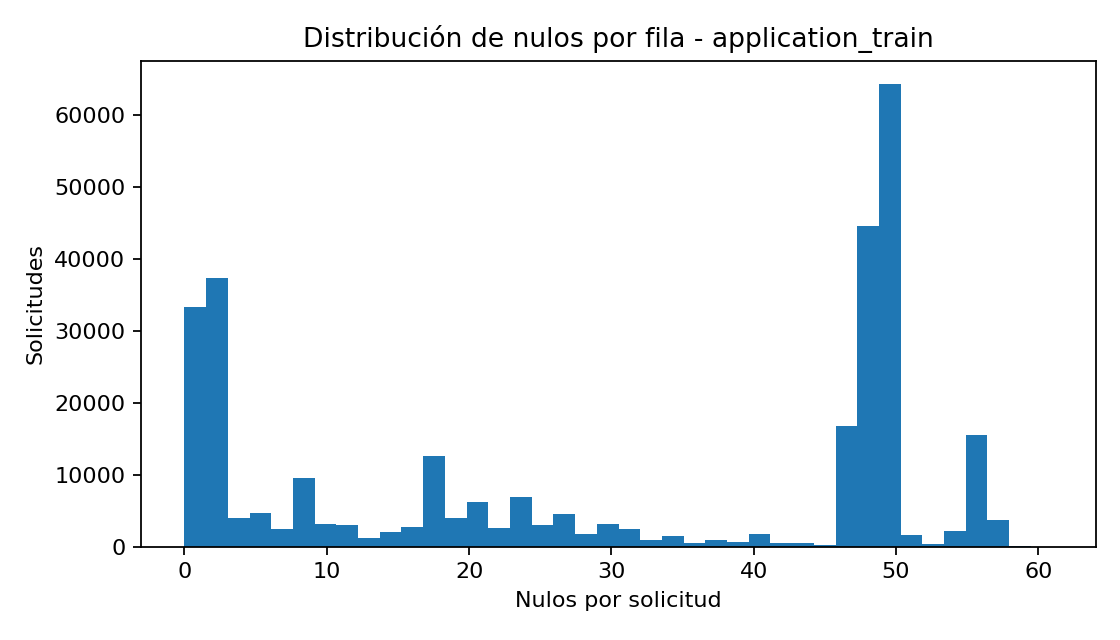

In [15]:
mostrar_tabla("faltantes_vs_target.csv", 15)
mostrar_fig("F_faltante_vs_target.png")
mostrar_tabla("faltantes_por_fila.csv")
mostrar_fig("F_nulos_por_fila.png", 520)

## 7. Valores atípicos (3.2)

{'filas_centinela': 55374, 'pct': 18.0072, 'mora_centinela_%': np.float64(5.4), 'mora_resto_%': np.float64(8.66), 'tipos_ingreso_en_centinela': {'Pensioner': 55352, 'Unemployed': 22}}


,columna,n,min,p1,mediana,p99,p99_9,max,q1,q3,n_fuera_1.5IQR,pct_fuera_1.5IQR,n_fuera_3IQR,pct_fuera_3IQR
0,AMT_INCOME_TOTAL,307511,25650.0,45000.00,147150.0,472500.0,900000.0,117000000.0,112500.0,202500.0,14035,4.5641,3014,0.9801
1,AMT_CREDIT,307511,45000.0,76410.00,513531.0,1854000.0,2517300.0,4050000.0,270000.0,808650.0,6562,2.1339,444,0.1444
2,AMT_ANNUITY,307499,1615.5,6182.91,24903.0,70006.5,110047.5,258025.5,16524.0,34596.0,7504,2.4403,1024,0.3330
3,AMT_GOODS_PRICE,307233,40500.0,67500.00,450000.0,1800000.0,2250000.0,4050000.0,238500.0,679500.0,14728,4.7938,1090,0.3548
4,DAYS_BIRTH,307511,-25229.0,-24419.00,-15750.0,-8263.0,-7759.0,-7489.0,-19682.0,-12413.0,0,0.0000,0,0.0000
5,DAYS_EMPLOYED,252137,-17912.0,-11338.28,-1648.0,-111.0,-54.0,0.0,-3175.0,-767.0,15149,6.0082,3832,1.5198
6,CNT_CHILDREN,307511,0.0,0.00,0.0,3.0,4.0,19.0,0.0,1.0,4272,1.3892,126,0.0410
7,CNT_FAM_MEMBERS,307509,1.0,1.00,2.0,5.0,6.0,20.0,2.0,3.0,4007,1.3031,121,0.0393
8,OBS_30_CNT_SOCIAL_CIRCLE,306490,0.0,0.00,0.0,10.0,17.0,348.0,0.0,2.0,19971,6.5160,6161,2.0102
9,OBS_60_CNT_SOCIAL_CIRCLE,306490,0.0,0.00,0.0,10.0,16.0,344.0,0.0,2.0,19564,6.3832,5985,1.9528


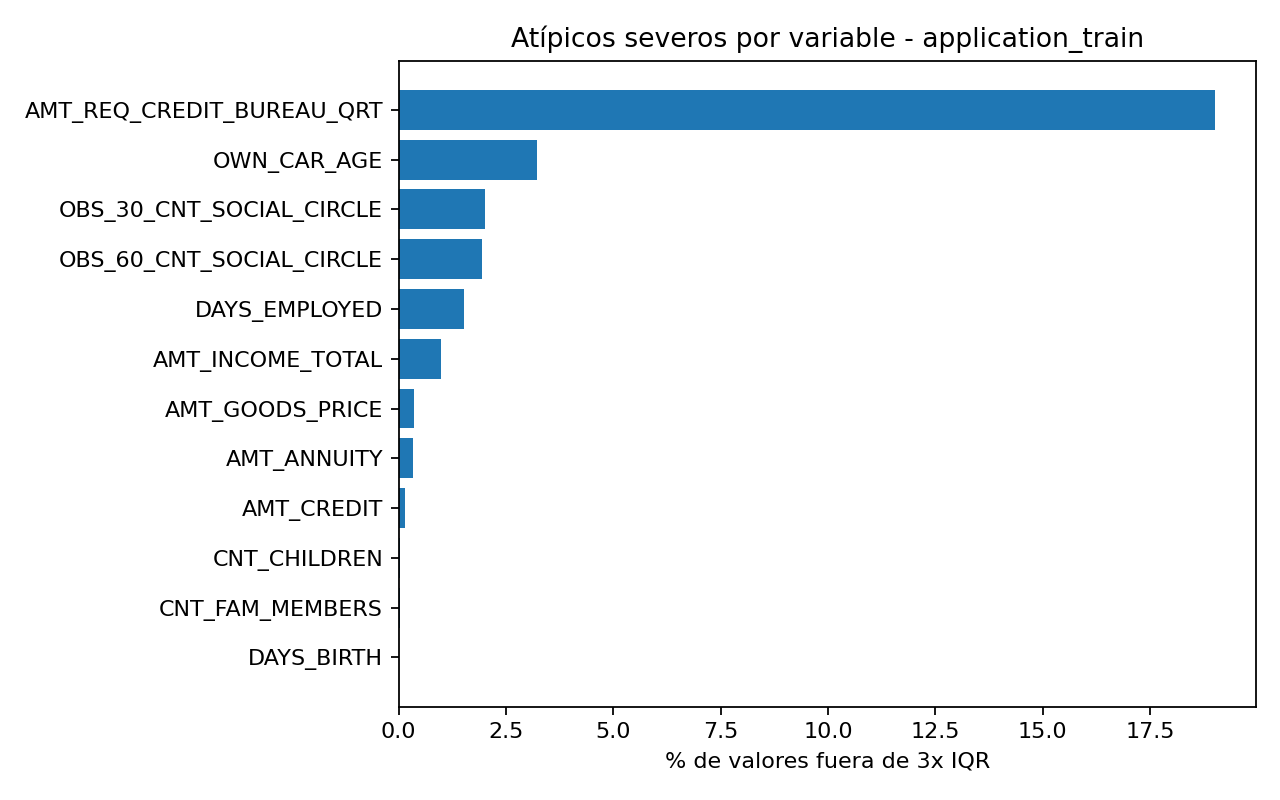

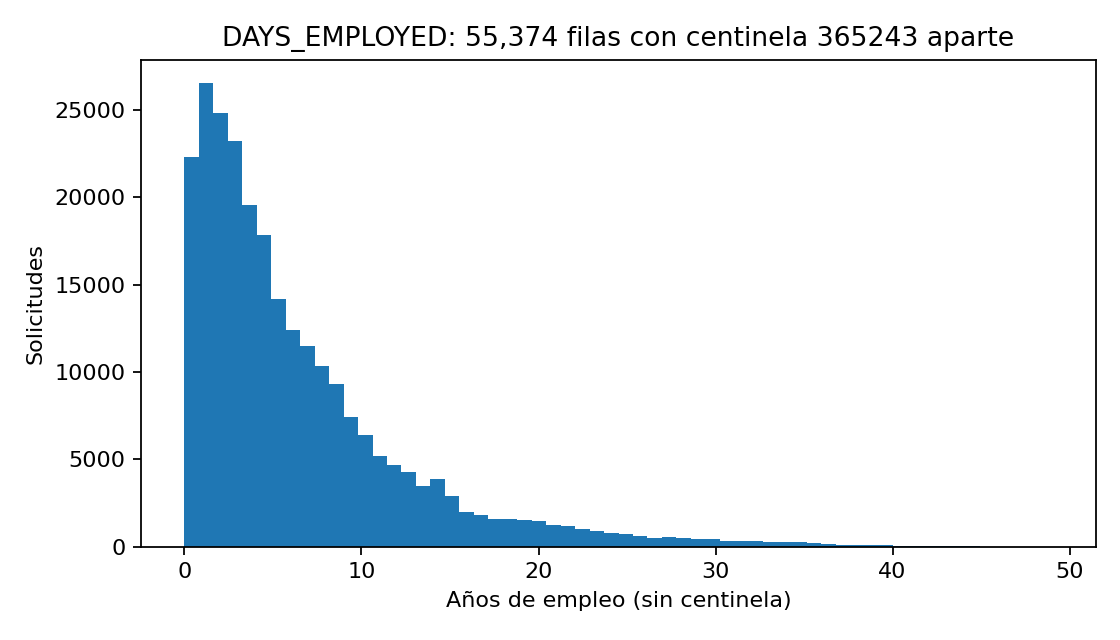

,n,min,p1,mediana,p99,p99_9,max,q1,q3,n_fuera_1.5IQR,pct_fuera_1.5IQR,n_fuera_3IQR,pct_fuera_3IQR,tabla,columna
0,1716415,0.000000e+00,0.000000,125518.500000,3.700916e+06,1.102100e+07,5.850000e+08,51300.000000,315000.000000,187998,10.9529,116592,6.7928,bureau,AMT_CREDIT_SUM
1,1458759,-4.705600e+06,0.000000,0.000000,2.259728e+06,8.841941e+06,1.701000e+08,0.000000,40153.500000,280455,19.2256,219502,15.0472,bureau,AMT_CREDIT_SUM_DEBT
2,1716428,0.000000e+00,0.000000,0.000000,0.000000e+00,5.257300e+01,2.792000e+03,0.000000,0.000000,4217,0.2457,4217,0.2457,bureau,CREDIT_DAY_OVERDUE
3,1716428,-2.922000e+03,-2867.000000,-987.000000,-3.800000e+01,-1.000000e+01,0.000000e+00,-1666.000000,-474.000000,0,0.0000,0,0.0000,bureau,DAYS_CREDIT
4,489637,0.000000e+00,0.000000,0.000000,1.184519e+05,9.500085e+05,1.184534e+08,0.000000,13500.000000,43918,8.9695,18992,3.8788,bureau,AMT_ANNUITY
5,27299925,-9.600000e+01,-91.000000,-25.000000,0.000000e+00,0.000000e+00,0.000000e+00,-46.000000,-11.000000,0,0.0000,0,0.0000,bureau_balance,MONTHS_BALANCE
6,1670214,0.000000e+00,0.000000,71046.000000,1.350000e+06,2.250000e+06,6.905160e+06,18720.000000,180360.000000,208019,12.4546,120744,7.2293,previous_application,AMT_APPLICATION
7,1670213,0.000000e+00,0.000000,80541.000000,1.515378e+06,2.517300e+06,6.905160e+06,24160.500000,216418.500000,179989,10.7764,95710,5.7304,previous_application,AMT_CREDIT
8,1297979,0.000000e+00,2137.175122,11250.000000,6.968579e+04,1.192314e+05,4.180582e+05,6321.779785,20658.419922,82762,6.3762,18774,1.4464,previous_application,AMT_ANNUITY
9,1670214,-2.922000e+03,-2835.000000,-581.000000,-1.400000e+01,-3.000000e+00,-1.000000e+00,-1300.000000,-280.000000,17571,1.0520,0,0.0000,previous_application,DAYS_DECISION


In [16]:
analisis_atipicos(df, out, resumen)
print(resumen.get("centinela_days_employed"))
mostrar_tabla("atipicos_application_train.csv")
mostrar_fig("F_atipicos_pct.png")
mostrar_fig("F_days_employed.png", 520)
if (out / "tablas" / "atipicos_secundarias.csv").exists():
    mostrar_tabla("atipicos_secundarias.csv")

## 8. Duplicados, errores e inconsistencias (3.2)

In [17]:
duplicados_application(df, out, resumen)
revisar_inconsistencias(df, out, resumen)
mostrar_tabla("duplicados_application_train.csv")
mostrar_tabla("inconsistencias_application_train.csv", 40)

,filas,duplicados_fila_completa,SK_ID_CURR_repetidos
0,307511,0,0


,chequeo,filas_afectadas,pct
0,DAYS_BIRTH >= 0 (debe ser negativo),0,0.0000
1,Edad < 18 o > 100 años,0,0.0000
2,DAYS_EMPLOYED = centinela 365243,55374,18.0072
3,DAYS_EMPLOYED positivo distinto del centinela,0,0.0000
4,Años empleado > edad,0,0.0000
5,Empezó a trabajar antes de los 14 años,0,0.0000
6,CODE_GENDER = XNA,4,0.0013
7,ORGANIZATION_TYPE = XNA,55374,18.0072
8,ORGANIZATION_TYPE = XNA y centinela de empleo ...,55374,18.0072
9,CNT_FAM_MEMBERS < CNT_CHILDREN,0,0.0000


## 9. Selección de columnas y limpieza v1
Excluye columnas, convierte centinelas y `XNA` a NaN, topea al p99.9 con banderas, crea banderas `FALTA_*` y reduce tipos.

> Los topes de percentil se calculan aquí sobre todo `application_train` para documentar. En el pipeline final deben recalcularse solo con train, después del split.

In [18]:
excl = seleccion_columnas(df, nulos_sec, UMBRAL_VACIO, UMBRAL_CONSTANTE, out, resumen)
display(excl)
df_clean = limpiar_application(df, excl, firmas, UMBRAL_BANDERA, out, resumen, GUARDAR_LIMPIO)
mostrar_tabla("registro_limpieza.csv")
mostrar_tabla("antes_despues_application_train.csv")

,tabla,columna,motivo,decision
0,application_train,FLAG_MOBIL,casi constante (valor dominante 99.9997%),excluir
1,application_train,FLAG_DOCUMENT_2,casi constante (valor dominante 99.9958%),excluir
2,application_train,FLAG_DOCUMENT_4,casi constante (valor dominante 99.9919%),excluir
3,application_train,FLAG_DOCUMENT_7,casi constante (valor dominante 99.9808%),excluir
4,application_train,FLAG_DOCUMENT_10,casi constante (valor dominante 99.9977%),excluir
5,application_train,FLAG_DOCUMENT_12,casi constante (valor dominante 99.9993%),excluir
6,application_train,FLAG_DOCUMENT_17,casi constante (valor dominante 99.9733%),excluir
7,application_train,FLAG_DOCUMENT_19,casi constante (valor dominante 99.9405%),excluir
8,application_train,FLAG_DOCUMENT_20,casi constante (valor dominante 99.9493%),excluir
9,application_train,FLAG_DOCUMENT_21,casi constante (valor dominante 99.9665%),excluir


[10:18:23] Guardado application_train_clean.parquet


,paso,detalle,filas
0,columnas excluidas,"FLAG_MOBIL, FLAG_DOCUMENT_2, FLAG_DOCUMENT_4, ...",NaN
1,DAYS_EMPLOYED centinela -> NaN + FLAG_NO_EMPLEADO,NaN,55374.0
2,CODE_GENDER: XNA -> NaN,NaN,4.0
3,ORGANIZATION_TYPE: XNA -> NaN,NaN,55374.0
4,AMT_INCOME_TOTAL: topeo p99.9,tope=900000.00,278.0
5,OBS_30_CNT_SOCIAL_CIRCLE: topeo p99.9,tope=17.00,222.0
6,OBS_60_CNT_SOCIAL_CIRCLE: topeo p99.9,tope=16.00,292.0
7,AMT_REQ_CREDIT_BUREAU_QRT: topeo p99.9,tope=4.00,108.0
8,banderas FALTA_*,24 banderas (umbral 5.0%),NaN


,momento,filas,columnas,nulos_totales,memoria_MB
0,antes,307511,122,9152465,529.5
1,después,307511,141,9263217,107.0


,columna,tope_p99_9,filas_topeadas,max_antes,max_despues,media_antes,media_despues,desv_antes,desv_despues
0,AMT_INCOME_TOTAL,900000.0,278,117000000.0,900000.0,168797.919297,167771.350678,237123.146279,91928.892668
1,OBS_30_CNT_SOCIAL_CIRCLE,17.0,222,348.0,17.0,1.422245,1.418356,2.400989,2.295219
2,OBS_60_CNT_SOCIAL_CIRCLE,16.0,292,344.0,16.0,1.405292,1.400578,2.379803,2.269646
3,AMT_REQ_CREDIT_BUREAU_QRT,4.0,108,261.0,4.0,0.265474,0.263816,0.794056,0.606350


,bandera,cubre_columnas,pct_ausente
0,FALTA_COMMONAREA_AVG,3,69.8723
1,FALTA_NONLIVINGAPARTMENTS_MEDI,3,69.4330
2,FALTA_FONDKAPREMONT_MODE,1,68.3862
3,FALTA_LIVINGAPARTMENTS_AVG,3,68.3550
4,FALTA_FLOORSMIN_MODE,3,67.8486
5,FALTA_YEARS_BUILD_AVG,3,66.4978
6,FALTA_OWN_CAR_AGE,1,65.9908
7,FALTA_LANDAREA_MEDI,3,59.3767
8,FALTA_BASEMENTAREA_MODE,3,58.5160
9,FALTA_EXT_SOURCE_1,1,56.3811


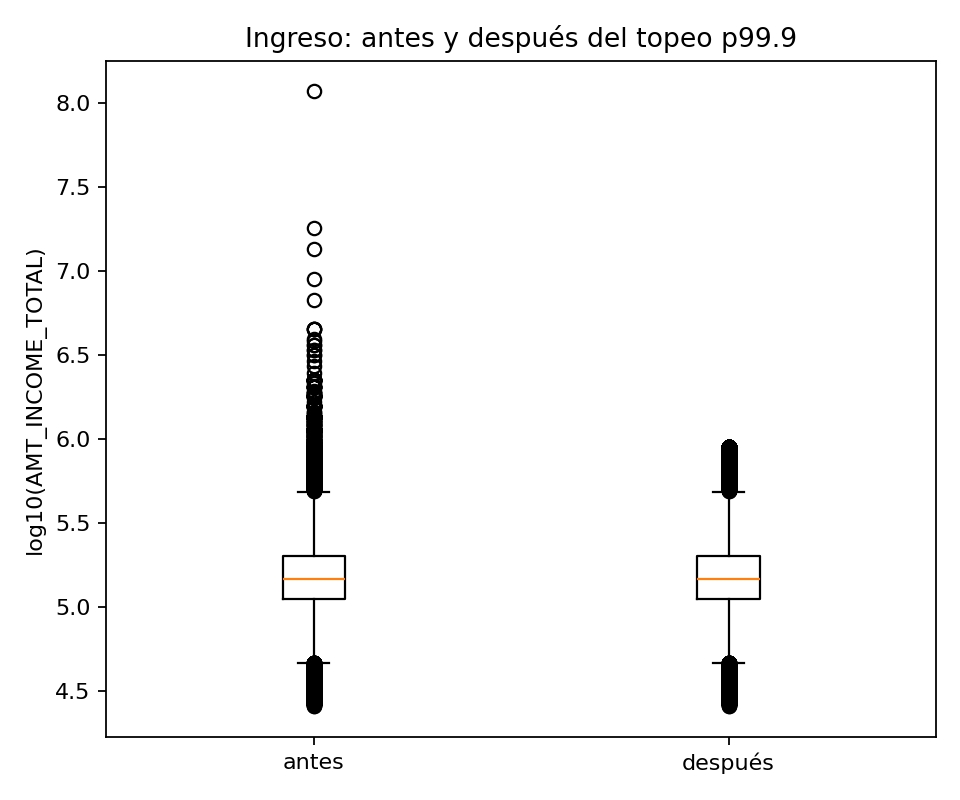

In [19]:
mostrar_tabla("topeo_antes_despues.csv")
mostrar_tabla("banderas_ausencia_creadas.csv")
mostrar_fig("F_ingreso_antes_despues.png", 400)

## 10. Cierre: guardar resumen y empaquetar

In [20]:
with open(OUT_DIR / "resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False, default=a_json)
zip_path = shutil.make_archive("salida_fase3", "zip", OUT_DIR)
print("Listo. Enviar:", zip_path)

Listo. Enviar: /content/salida_fase3.zip
